## Exploratory Data Analysis (EDA) – Introduction

Exploratory Data Analysis (EDA) was performed on the Nassau Candy Distributor dataset to understand shipping performance, product sales, profitability, and regional distribution patterns. The analysis involved examining data quality, identifying missing values and duplicates, analyzing shipping lead time, and studying the relationship between shipping modes, regions, and product performance.

Various statistical methods and visualizations were used to identify patterns, trends, and potential operational inefficiencies. The objective of EDA was to identify areas with higher shipping lead times and understand how shipping performance varies across regions and products. These findings provide a foundation for predictive modeling and factory reallocation scenario analysis to support data-driven business decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karo — apni actual file ka naam use karna
df = pd.read_csv(r"C:\Users\sachi\Downloads\Nassau Candy Distributor.csv")

# Dataset ka size
print("Rows and Columns:", df.shape)

# Pehli 5 rows
display(df.head())

# Column names aur data types
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Numerical columns ka statistical summary
display(df.describe())

Rows and Columns: (10194, 18)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


In [ ]:
# Dataset load karo
df = pd.read_csv("nassau_candy.csv")

# Column names se extra spaces remove karo
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

In [2]:
# Columns, non-null values aur data types check karo
df.info()

# Numerical aur categorical columns ka overview
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  int64  
 6   Country/Region  10194 non-null  object 
 7   City            10194 non-null  object 
 8   State/Province  10194 non-null  object 
 9   Postal Code     10194 non-null  object 
 10  Division        10194 non-null  object 
 11  Region          10194 non-null  object 
 12  Product ID      10194 non-null  object 
 13  Product Name    10194 non-null  object 
 14  Sales           10194 non-null  float64
 15  Units           10194 non-null  int64  
 16  Gross Profit    10194 non-null  float64
 17  Cost            10194 non-null 

In [3]:
# Missing values ki count aur percentage
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Row ID,0,0.0
Order ID,0,0.0
Gross Profit,0,0.0
Units,0,0.0
Sales,0,0.0
Product Name,0,0.0
Product ID,0,0.0
Region,0,0.0
Division,0,0.0
Postal Code,0,0.0


In [4]:
# Complete duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Unique Row IDs aur duplicate IDs
print("Unique Row IDs:", df["Row ID"].nunique())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

# Order ID repeat hona zaroori nahi ki error ho
print("Unique Orders:", df["Order ID"].nunique())
print("Total Records:", len(df))

Duplicate Rows: 0
Unique Row IDs: 10194
Duplicate Row IDs: 0
Unique Orders: 8549
Total Records: 10194


In [5]:
# Original date values ko parse karne se pehle preserve karo
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(
        df[col],
        format="%d-%m-%Y",
        errors="coerce"
    )

# Invalid dates check karo
print("Missing/Invalid Order Dates:", df["Order Date"].isna().sum())
print("Missing/Invalid Ship Dates:", df["Ship Date"].isna().sum())

display(df[["Order Date", "Ship Date"]].head())

Missing/Invalid Order Dates: 0
Missing/Invalid Ship Dates: 0


,Order Date,Ship Date
0,2024-01-03,2026-06-30
1,2024-01-04,2026-07-01
2,2024-01-04,2026-07-01
3,2024-01-04,2026-07-01
4,2024-01-05,2026-07-05


In [6]:
# Order date se shipment date tak ke days
df["Shipping_Lead_Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Invalid lead times check karo
print("Negative Lead Times:",
      (df["Shipping_Lead_Time"] < 0).sum())

print("Zero-Day Lead Times:",
      (df["Shipping_Lead_Time"] == 0).sum())

display(df["Shipping_Lead_Time"].describe())

Negative Lead Times: 0
Zero-Day Lead Times: 0


count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping_Lead_Time, dtype: float64

In [7]:
# Business data mein unusual values check karo
print("Negative Sales:", (df["Sales"] < 0).sum())
print("Negative Cost:", (df["Cost"] < 0).sum())
print("Negative Gross Profit:", (df["Gross Profit"] < 0).sum())
print("Zero/Negative Units:", (df["Units"] <= 0).sum())

# Sales ke comparison mein gross profit
df["Profit_Margin_Percent"] = np.where(
    df["Sales"] > 0,
    (df["Gross Profit"] / df["Sales"]) * 100,
    np.nan
)

display(
    df[[
        "Sales",
        "Cost",
        "Gross Profit",
        "Units",
        "Profit_Margin_Percent"
    ]].describe().round(2)
)

Negative Sales: 0
Negative Cost: 0
Negative Gross Profit: 0
Zero/Negative Units: 0


,Sales,Cost,Gross Profit,Units,Profit_Margin_Percent
count,10194.00,10194.00,10194.00,10194.00,10194.00
mean,13.91,4.74,9.17,3.79,66.51
std,11.34,5.06,6.64,2.23,6.72
min,1.25,0.60,0.25,1.00,7.69
25%,7.20,2.40,4.90,2.00,65.33
50%,10.80,3.60,7.47,3.00,66.67
75%,18.00,5.70,12.25,5.00,69.44
max,260.00,130.00,130.00,14.00,80.00


In [8]:
# Current cleaned working dataset save karo
df.to_csv("nassau_candy_cleaned.csv", index=False)

print("Cleaned working dataset saved successfully!")

Cleaned working dataset saved successfully!


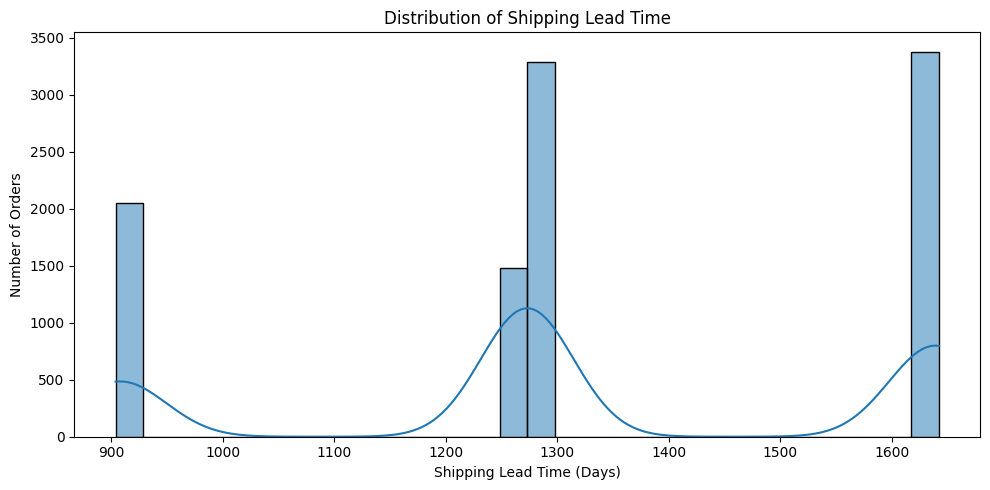

In [9]:
# Lead time ki distribution samjho
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Shipping_Lead_Time",
    bins=30,
    kde=True
)

plt.title("Distribution of Shipping Lead Time")
plt.xlabel("Shipping Lead Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

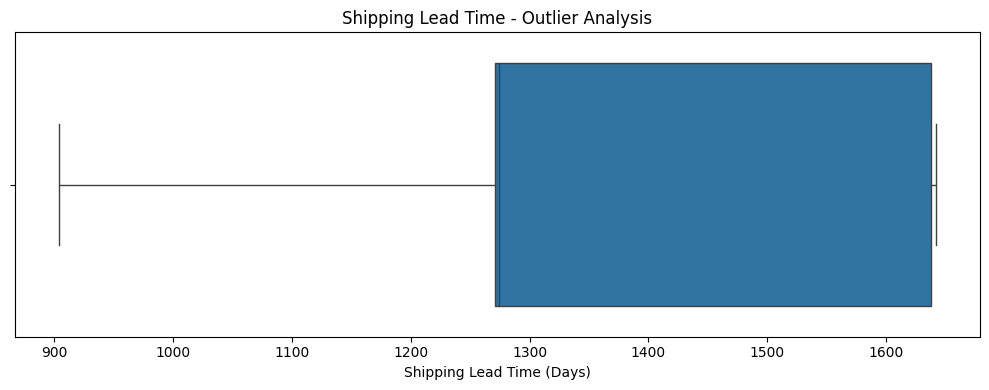

In [10]:
# Outliers aur spread identify karo
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="Shipping_Lead_Time"
)

plt.title("Shipping Lead Time - Outlier Analysis")
plt.xlabel("Shipping Lead Time (Days)")
plt.tight_layout()
plt.show()

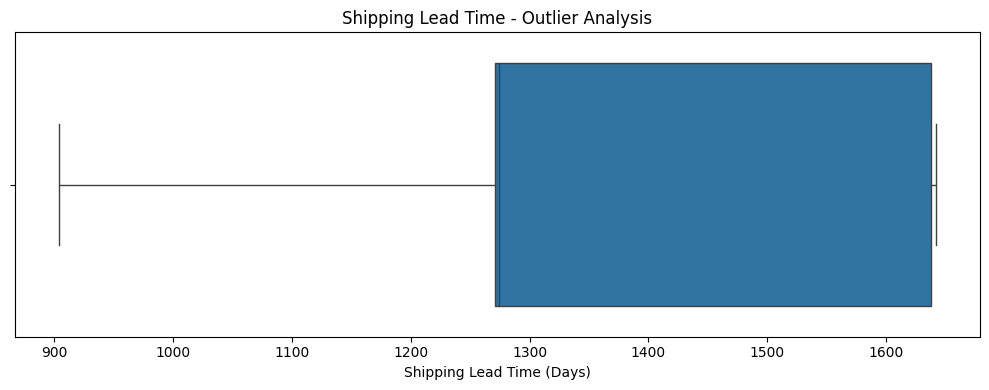

In [11]:
# Outliers aur spread identify karo
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="Shipping_Lead_Time"
)

plt.title("Shipping Lead Time - Outlier Analysis")
plt.xlabel("Shipping Lead Time (Days)")
plt.tight_layout()
plt.show()

,count,mean,median
Ship Mode,,,
First Class,1548,1338.28,1272.0
Same Day,547,1333.44,1269.0
Second Class,1979,1323.85,1273.0
Standard Class,6120,1314.33,1274.0


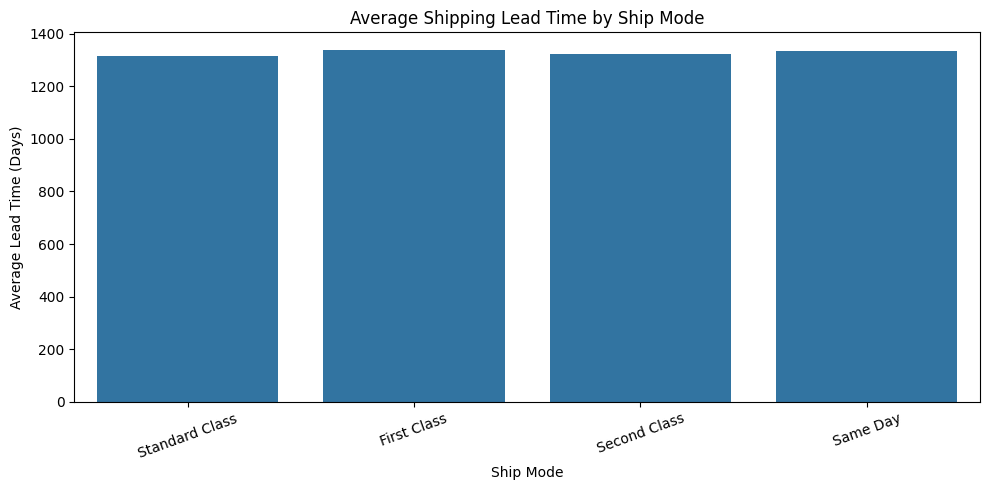

In [12]:
# Har shipping mode ka average aur median lead time
ship_mode_analysis = (
    df.groupby("Ship Mode")["Shipping_Lead_Time"]
      .agg(["count", "mean", "median"])
      .round(2)
      .sort_values("mean", ascending=False)
)

display(ship_mode_analysis)

# Bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Ship Mode",
    y="Shipping_Lead_Time",
    estimator="mean",
    errorbar=None
)

plt.title("Average Shipping Lead Time by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:** First Class has the highest average shipping lead time (1,338.28 days), while Standard Class has the lowest (1,314.33 days) and the highest order count (6,120). The unusually high lead times should be validated before drawing business conclusions.

,count,mean,median
Region,,,
Interior,2335,1323.09,1274.0
Atlantic,2986,1322.75,1274.0
Pacific,3253,1322.19,1274.0
Gulf,1620,1311.37,1274.0


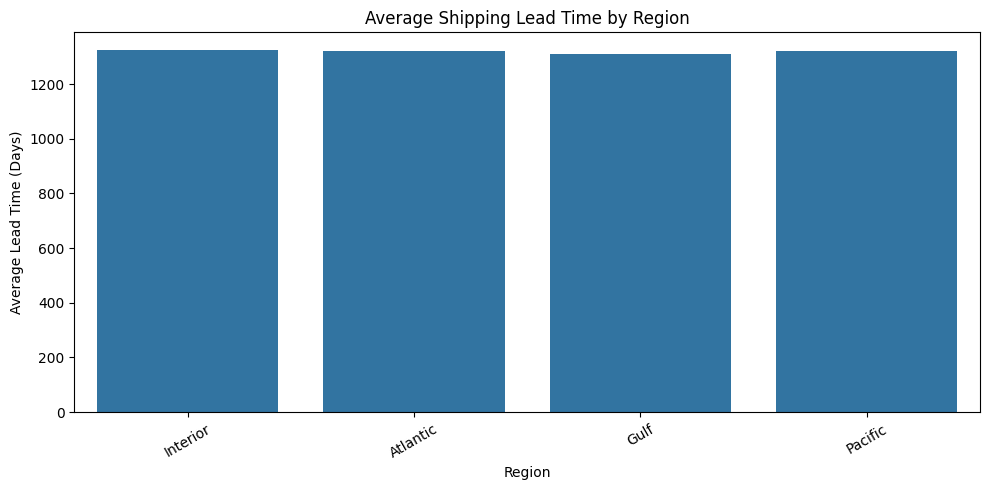

In [13]:
# Region ke according shipping performance
region_analysis = (
    df.groupby("Region")["Shipping_Lead_Time"]
      .agg(["count", "mean", "median"])
      .round(2)
      .sort_values("mean", ascending=False)
)

display(region_analysis)

# Visual comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Region",
    y="Shipping_Lead_Time",
    estimator="mean",
    errorbar=None
)

plt.title("Average Shipping Lead Time by Region")
plt.xlabel("Region")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [14]:
# Products ki sales aur profit compare karo
product_analysis = (
    df.groupby(["Product ID", "Product Name"], dropna=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Gross Profit", "sum"),
          Total_Units=("Units", "sum")
      )
      .reset_index()
)

product_analysis["Profit_Margin_Percent"] = np.where(
    product_analysis["Total_Sales"] > 0,
    product_analysis["Total_Profit"]
    / product_analysis["Total_Sales"] * 100,
    np.nan
)

# Low profit margin wale 10 products
display(
    product_analysis
    .sort_values("Profit_Margin_Percent")
    .head(10)
    .round(2)
)

,Product ID,Product Name,Total_Sales,Total_Profit,Total_Units,Profit_Margin_Percent
7,OTH-KAZ-38000,Kazookles,1205.75,92.75,371,7.69
10,SUG-FUN-75000,Fun Dip,12.00,4.80,8,40.00
13,SUG-NER-92000,Nerds,15.00,7.00,10,46.67
14,SUG-SWE-91000,SweeTARTS,61.50,28.70,41,46.67
8,OTH-LIC-15000,Lickable Wallpaper,7860.00,3930.00,393,50.00
6,OTH-GUM-21000,Wonka Gum,597.50,310.70,478,52.00
5,OTH-FIZ-56000,Fizzy Lifting Drinks,78.75,47.25,21,60.00
12,SUG-LAF-25000,Laffy Taffy,53.73,33.48,27,62.31
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,26867.75,17443.37,8267,64.92
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,7596,65.33


**Insight:** ***Wonka Bar – Triple Dazzle Caramel generated the highest sales (28,485) and profit (18,610.20), with a profit margin of 65.33%. In contrast, Fun Dip had the lowest sales (12.00). Lickable Wallpaper achieved a strong 50% profit margin, highlighting differences in product profitability.***

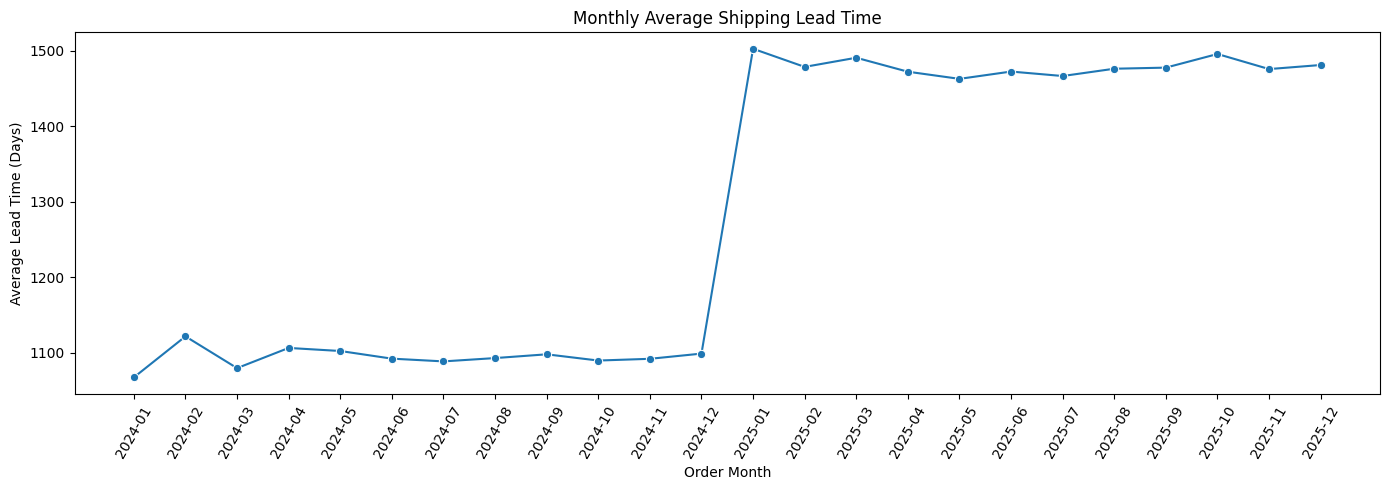

In [15]:
# Monthly average shipping lead time
monthly_analysis = (
    df.dropna(subset=["Order Date", "Shipping_Lead_Time"])
      .assign(
          Month=lambda x: x["Order Date"].dt.to_period("M").astype(str)
      )
      .groupby("Month")["Shipping_Lead_Time"]
      .mean()
      .reset_index(name="Average_Lead_Time")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_analysis,
    x="Month",
    y="Average_Lead_Time",
    marker="o"
)

plt.title("Monthly Average Shipping Lead Time")
plt.xlabel("Order Month")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [16]:
# Required columns check karo
required_cols = [
    "Product ID", "Region", "Ship Mode",
    "Division", "Units", "Order Date",
    "Shipping_Lead_Time"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All required columns available!")

print("Dataset shape:", df.shape)

All required columns available!
Dataset shape: (10194, 20)


In [17]:
# Dates datetime format mein honi chahiye
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce", dayfirst=True
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce", dayfirst=True
)

df["Shipping_Lead_Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [18]:
# Order Date se useful features
df["Order_Month"] = df["Order Date"].dt.month
df["Order_Weekday"] = df["Order Date"].dt.dayofweek

# Monday = 0, Sunday = 6
display(
    df[[
        "Order Date",
        "Order_Month",
        "Order_Weekday",
        "Shipping_Lead_Time"
    ]].head()
)

,Order Date,Order_Month,Order_Weekday,Shipping_Lead_Time
0,2024-01-03,1,2,909
1,2024-01-04,1,3,909
2,2024-01-04,1,3,909
3,2024-01-04,1,3,909
4,2024-01-05,1,4,912


In [21]:
# Original dataset ko preserve karke modeling copy banao
df_model = df.copy()

# Invalid/missing target values remove karo
df_model = df_model[
    df_model["Shipping_Lead_Time"].notna()
    & (df_model["Shipping_Lead_Time"] >= 0)
].copy()

print("Rows available for modeling:", len(df_model))
print("Removed invalid target rows:", len(df) - len(df_model))

Rows available for modeling: 10194
Removed invalid target rows: 0


In [22]:
# IQR limits calculate karo
Q1 = df_model["Shipping_Lead_Time"].quantile(0.25)
Q3 = df_model["Shipping_Lead_Time"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_model[
    (df_model["Shipping_Lead_Time"] < lower_limit)
    | (df_model["Shipping_Lead_Time"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Potential outlier rows:", len(outliers))

display(
    outliers[
        ["Order ID", "Product ID", "Region",
         "Ship Mode", "Shipping_Lead_Time"]
    ].head(10)
)

Lower limit: 720.5
Upper limit: 2188.5
Potential outlier rows: 0


,Order ID,Product ID,Region,Ship Mode,Shipping_Lead_Time


In [23]:
# Extreme lead-time values ko exclude karke experimental dataset
df_iqr = df_model[
    df_model["Shipping_Lead_Time"].between(
        lower_limit, upper_limit
    )
].copy()

print("Original valid rows:", len(df_model))
print("Rows after IQR filtering:", len(df_iqr))
print("Excluded rows:", len(df_model) - len(df_iqr))

Original valid rows: 10194
Rows after IQR filtering: 10194
Excluded rows: 0


In [24]:
# Features available at order time
categorical_features = [
    "Product ID",
    "Region",
    "Ship Mode",
    "Division"
]

numerical_features = [
    "Units",
    "Order_Month",
    "Order_Weekday"
]

target = "Shipping_Lead_Time"

feature_cols = categorical_features + numerical_features

# Missing feature values ko preprocessing pipeline handle karegi
X = df_iqr[feature_cols].copy()
y = df_iqr[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature matrix shape: (10194, 7)
Target shape: (10194,)


,Product ID,Region,Ship Mode,Division,Units,Order_Month,Order_Weekday
0,CHO-MIL-31000,Interior,Standard Class,Chocolate,2,1,2
1,CHO-TRI-54000,Interior,Standard Class,Chocolate,2,1,3
2,CHO-NUT-13000,Interior,Standard Class,Chocolate,3,1,3
3,CHO-SCR-58000,Interior,Standard Class,Chocolate,3,1,3
4,CHO-TRI-54000,Atlantic,Standard Class,Chocolate,3,1,4


0    909
1    909
2    909
3    909
4    912
Name: Shipping_Lead_Time, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 8155
Testing rows: 2039


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Dono pipelines combine karo
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Training data par fit; testing data par sirf transform
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Training-ready matrix:", X_train_ready.shape)
print("Testing-ready matrix:", X_test_ready.shape)

Training-ready matrix: (8155, 29)
Testing-ready matrix: (2039, 29)


In [27]:
# Encoding ke baad naye feature names
encoded_feature_names = preprocessor.get_feature_names_out()

print("Total encoded features:", len(encoded_feature_names))
print(encoded_feature_names[:30])

Total encoded features: 29
['num__Units' 'num__Order_Month' 'num__Order_Weekday'
 'cat__Product ID_CHO-FUD-51000' 'cat__Product ID_CHO-MIL-31000'
 'cat__Product ID_CHO-NUT-13000' 'cat__Product ID_CHO-SCR-58000'
 'cat__Product ID_CHO-TRI-54000' 'cat__Product ID_OTH-FIZ-56000'
 'cat__Product ID_OTH-GUM-21000' 'cat__Product ID_OTH-KAZ-38000'
 'cat__Product ID_OTH-LIC-15000' 'cat__Product ID_SUG-EVE-47000'
 'cat__Product ID_SUG-FUN-75000' 'cat__Product ID_SUG-HAI-55000'
 'cat__Product ID_SUG-LAF-25000' 'cat__Product ID_SUG-NER-92000'
 'cat__Product ID_SUG-SWE-91000' 'cat__Region_Atlantic' 'cat__Region_Gulf'
 'cat__Region_Interior' 'cat__Region_Pacific' 'cat__Ship Mode_First Class'
 'cat__Ship Mode_Same Day' 'cat__Ship Mode_Second Class'
 'cat__Ship Mode_Standard Class' 'cat__Division_Chocolate'
 'cat__Division_Other' 'cat__Division_Sugar']


In [28]:
from scipy import sparse

# Encoded matrix ko DataFrame mein convert karo
if sparse.issparse(X_train_ready):
    X_train_df = pd.DataFrame.sparse.from_spmatrix(
        X_train_ready,
        columns=encoded_feature_names,
        index=X_train.index
    )
    X_test_df = pd.DataFrame.sparse.from_spmatrix(
        X_test_ready,
        columns=encoded_feature_names,
        index=X_test.index
    )
else:
    X_train_df = pd.DataFrame(
        X_train_ready,
        columns=encoded_feature_names,
        index=X_train.index
    )
    X_test_df = pd.DataFrame(
        X_test_ready,
        columns=encoded_feature_names,
        index=X_test.index
    )

X_train_df.to_csv("X_train_ready.csv", index=False)
X_test_df.to_csv("X_test_ready.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Training-ready datasets saved successfully!")

Training-ready datasets saved successfully!


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

In [30]:
# Models define karo
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = []
trained_models = {}
predictions = {}

# Har model train aur evaluate karo
for name, model in models.items():

    # Model train karo
    model.fit(X_train_ready, y_train)

    # Test data par prediction
    y_pred = model.predict(X_test_ready)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2_Score": round(r2, 3)
    })

    trained_models[name] = model
    predictions[name] = y_pred

# Results table
results_df = pd.DataFrame(results)
display(results_df.sort_values("RMSE"))

,Model,MAE,RMSE,R2_Score
2,Gradient Boosting,214.375,259.882,0.045
0,Linear Regression,212.671,264.310,0.012
1,Random Forest,216.250,268.642,-0.020


In [31]:
# Lowest RMSE wale model ko select karo
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_model = trained_models[best_model_name]

print("Best model based on RMSE:", best_model_name)

Best model based on RMSE: Gradient Boosting


,Actual_Lead_Time,Predicted_Lead_Time
0,1269,1259.429212
1,1272,1351.377762
2,1273,1239.936958
3,1275,1390.222451
4,1640,1340.018165
5,1273,1228.585577
6,1273,1393.844625
7,1273,1343.180752
8,1270,1276.863232
9,1641,1359.764125


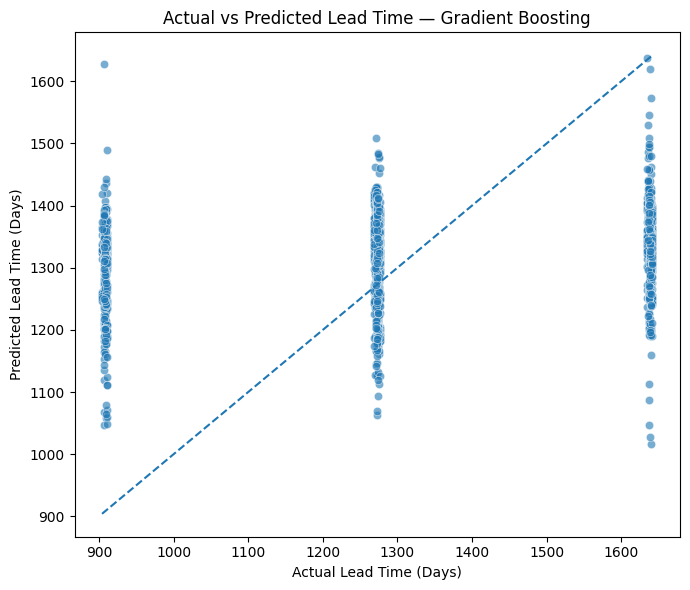

In [32]:
# Best model ki predictions
best_predictions = predictions[best_model_name]

comparison_df = pd.DataFrame({
    "Actual_Lead_Time": np.asarray(y_test),
    "Predicted_Lead_Time": best_predictions
})

display(comparison_df.head(15))

# Actual vs predicted scatter plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=comparison_df,
    x="Actual_Lead_Time",
    y="Predicted_Lead_Time",
    alpha=0.6
)

# Perfect prediction reference line
min_value = min(
    comparison_df["Actual_Lead_Time"].min(),
    comparison_df["Predicted_Lead_Time"].min()
)
max_value = max(
    comparison_df["Actual_Lead_Time"].max(),
    comparison_df["Predicted_Lead_Time"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Lead Time — {best_model_name}")
plt.xlabel("Actual Lead Time (Days)")
plt.ylabel("Predicted Lead Time (Days)")
plt.tight_layout()
plt.show()

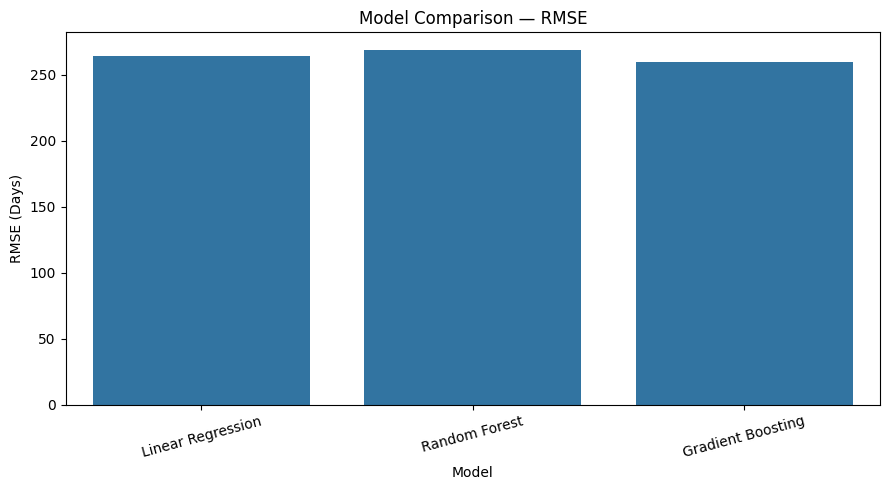

In [33]:
# RMSE comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison — RMSE")
plt.ylabel("RMSE (Days)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [35]:
results_df.to_csv("model_comparison_results.csv", index=False)
comparison_df.to_csv("best_model_predictions.csv", index=False)

print("Model results saved successfully!")

Model results saved successfully!


In [36]:
# Product-region-ship mode ke hisaab se performance summary
cluster_data = (
    df_model
    .groupby(
        ["Product ID", "Product Name", "Region", "Ship Mode"],
        dropna=False
    )
    .agg(
        Order_Count=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping_Lead_Time", "mean"),
        Median_Lead_Time=("Shipping_Lead_Time", "median"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
    .reset_index()
)

cluster_data["Average_Lead_Time"] = (
    cluster_data["Average_Lead_Time"].round(2)
)

print("Product-region combinations:", len(cluster_data))
display(cluster_data.head())

Product-region combinations: 154


,Product ID,Product Name,Region,Ship Mode,Order_Count,Average_Lead_Time,Median_Lead_Time,Total_Sales,Total_Profit,Total_Units
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,First Class,85,1338.50,1272.0,1375.2,916.8,382
1,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Same Day,18,1368.86,1269.0,270.0,180.0,75
2,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Second Class,82,1339.30,1273.0,1292.4,861.6,359
3,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Standard Class,270,1306.90,1274.0,4291.2,2860.8,1192
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Gulf,First Class,36,1299.54,1271.0,504.0,336.0,140


In [37]:
# Clustering features
cluster_features = [
    "Order_Count",
    "Average_Lead_Time",
    "Total_Sales",
    "Total_Profit",
    "Total_Units"
]

# Missing/infinite values handle karo
cluster_data[cluster_features] = (
    cluster_data[cluster_features]
    .replace([np.inf, -np.inf], np.nan)
)

cluster_data = cluster_data.dropna(
    subset=cluster_features
).copy()

print("Rows available for clustering:", len(cluster_data))

Rows available for clustering: 154


In [38]:
scaler_cluster = StandardScaler()

X_cluster = scaler_cluster.fit_transform(
    cluster_data[cluster_features]
)

print("Scaled clustering matrix:", X_cluster.shape)

Scaled clustering matrix: (154, 5)


C:\Users\sachi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sachi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sachi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\sachi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

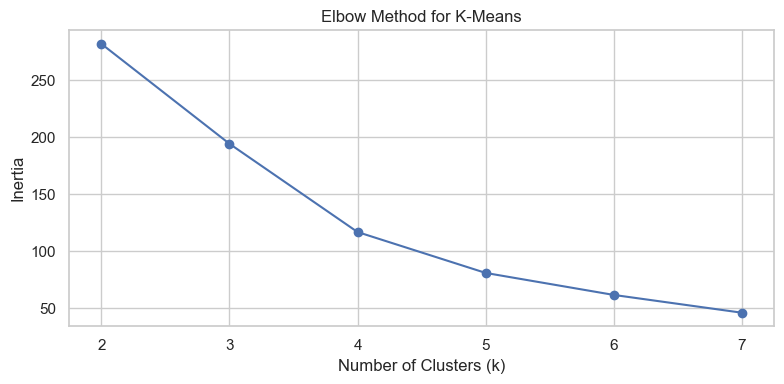

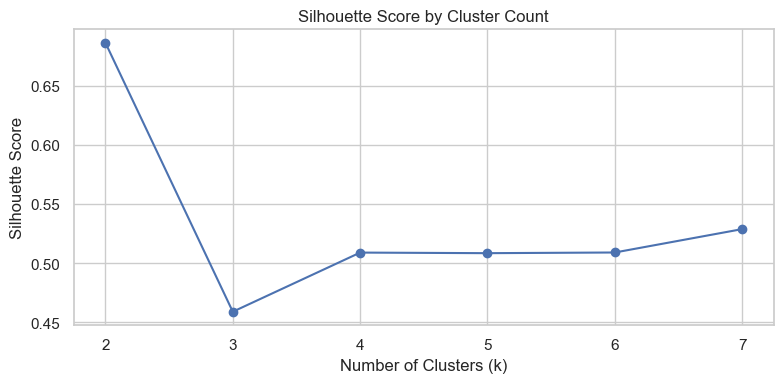

In [41]:
inertia_values = []
silhouette_values = []
k_values = range(2, min(8, len(cluster_data)))

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_cluster)
    inertia_values.append(km.inertia_)

    # Silhouette tabhi meaningful hai jab multiple clusters hon
    if len(set(labels)) > 1 and len(set(labels)) < len(labels):
        silhouette_values.append(
            silhouette_score(X_cluster, labels)
        )
    else:
        silhouette_values.append(np.nan)

# Elbow plot
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

# Silhouette score plot
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.title("Silhouette Score by Cluster Count")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

In [43]:
# Teen performance clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_data["Cluster"] = kmeans.fit_predict(X_cluster)

print("Clustering complete!")
display(cluster_data.head())

Clustering complete!


C:\Users\sachi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Product ID,Product Name,Region,Ship Mode,Order_Count,Average_Lead_Time,Median_Lead_Time,Total_Sales,Total_Profit,Total_Units,Cluster
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,First Class,85,1338.50,1272.0,1375.2,916.8,382,1
1,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Same Day,18,1368.86,1269.0,270.0,180.0,75,1
2,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Second Class,82,1339.30,1273.0,1292.4,861.6,359,1
3,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Atlantic,Standard Class,270,1306.90,1274.0,4291.2,2860.8,1192,2
4,CHO-FUD-51000,Wonka Bar - Fudge Mallows,Gulf,First Class,36,1299.54,1271.0,504.0,336.0,140,1


In [44]:
# Cluster-wise performance summary
cluster_summary = (
    cluster_data
    .groupby("Cluster")
    .agg(
        Combinations=("Product ID", "count"),
        Total_Orders=("Order_Count", "sum"),
        Average_Lead_Time=("Average_Lead_Time", "mean"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum"),
        Total_Units=("Total_Units", "sum")
    )
    .round(2)
    .sort_values("Average_Lead_Time", ascending=False)
)

display(cluster_summary)

,Combinations,Total_Orders,Average_Lead_Time,Total_Sales,Total_Profit,Total_Units
Cluster,,,,,,
0,24,102,1546.10,2638.37,1419.67,429
2,19,4810,1315.29,77644.86,52360.22,22000
1,111,3637,1283.89,61500.40,39662.91,16225


In [45]:
# Average lead time ke hisaab se sabse slow combinations
slow_combinations = (
    cluster_data
    .sort_values(
        ["Average_Lead_Time", "Order_Count"],
        ascending=[False, False]
    )
)

display(
    slow_combinations[
        [
            "Product ID",
            "Product Name",
            "Region",
            "Ship Mode",
            "Order_Count",
            "Average_Lead_Time",
            "Total_Sales",
            "Total_Profit",
            "Cluster"
        ]
    ].head(15)
)

,Product ID,Product Name,Region,Ship Mode,Order_Count,Average_Lead_Time,Total_Sales,Total_Profit,Cluster
133,SUG-EVE-47000,Everlasting Gobstopper,Interior,Standard Class,1,1641.00,30.00,24.00,0
84,OTH-FIZ-56000,Fizzy Lifting Drinks,Interior,Standard Class,1,1640.00,11.25,6.75,0
149,SUG-SWE-91000,SweeTARTS,Atlantic,Second Class,1,1640.00,7.50,3.50,0
138,SUG-HAI-55000,Hair Toffee,Atlantic,Standard Class,1,1639.00,22.50,17.50,0
147,SUG-LAF-25000,Laffy Taffy,Pacific,Standard Class,1,1638.00,1.99,1.24,0
153,SUG-SWE-91000,SweeTARTS,Pacific,Second Class,1,1638.00,6.00,2.80,0
80,OTH-FIZ-56000,Fizzy Lifting Drinks,Atlantic,First Class,1,1637.00,15.00,9.00,0
124,OTH-LIC-15000,Lickable Wallpaper,Interior,First Class,1,1637.00,180.00,90.00,0
91,OTH-GUM-21000,Wonka Gum,Gulf,Same Day,1,1635.00,5.00,2.60,0
125,OTH-LIC-15000,Lickable Wallpaper,Interior,Same Day,1,1635.00,80.00,40.00,0


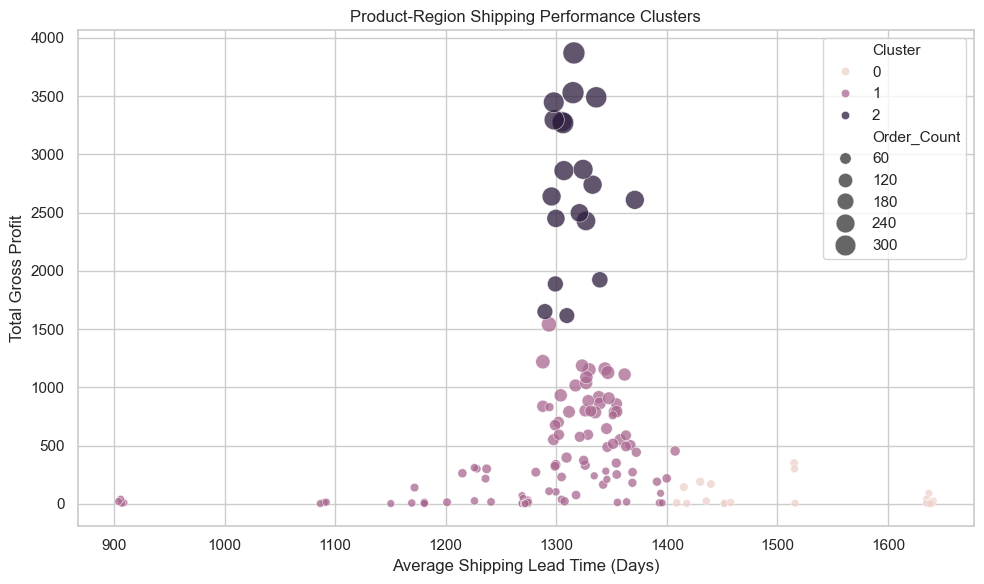

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_data,
    x="Average_Lead_Time",
    y="Total_Profit",
    hue="Cluster",
    size="Order_Count",
    sizes=(30, 250),
    alpha=0.75
)

plt.title("Product-Region Shipping Performance Clusters")
plt.xlabel("Average Shipping Lead Time (Days)")
plt.ylabel("Total Gross Profit")
plt.tight_layout()
plt.show()

In [47]:
cluster_data.to_csv(
    "shipping_performance_clusters.csv",
    index=False
)

cluster_summary.to_csv(
    "shipping_cluster_summary.csv"
)

print("Cluster results saved successfully!")

Cluster results saved successfully!


In [48]:
# Current factory ke hisaab se average shipping lead time
factory_insights = (
    df_scenario.dropna(subset=["Current_Factory", "Shipping_Lead_Time"])
    .groupby("Current_Factory")
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping_Lead_Time", "mean"),
        Median_Lead_Time=("Shipping_Lead_Time", "median"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .reset_index()
)

factory_insights = factory_insights.sort_values(
    "Average_Lead_Time", ascending=False
)

display(factory_insights.round(2))

# Highest average lead time wali factory
if not factory_insights.empty:
    slowest_factory = factory_insights.iloc[0]
    print("BUSINESS INSIGHT")
    print("----------------")
    print(
        f"Highest average lead time: {slowest_factory['Current_Factory']}"
    )
    print(
        f"Average lead time: {slowest_factory['Average_Lead_Time']:.2f} days"
    )
    print(
        f"Orders analyzed: {int(slowest_factory['Total_Orders'])}"
    )

NameError: name 'df_scenario' is not defined

In [52]:
# Region aur shipping mode ke according performance check karna
region_insights = (
    df_scenario.dropna(subset=["Shipping_Lead_Time"])
    .groupby(["Region", "Ship Mode"])
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping_Lead_Time", "mean"),
        Median_Lead_Time=("Shipping_Lead_Time", "median")
    )
    .reset_index()
    .sort_values("Average_Lead_Time", ascending=False)
)

display(region_insights.round(2))

# Sabse zyada average lead time wali region-mode combination
if not region_insights.empty:
    slowest_route_group = region_insights.iloc[0]
    print("SLOW SHIPPING INSIGHT")
    print("---------------------")
    print(f"Region: {slowest_route_group['Region']}")
    print(f"Ship Mode: {slowest_route_group['Ship Mode']}")
    print(
        f"Average lead time: "
        f"{slowest_route_group['Average_Lead_Time']:.2f} days"
    )

NameError: name 'df_scenario' is not defined

In [53]:
# Factory master data from your project brief
factories = pd.DataFrame({
    "Factory": [
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory"
    ],
    "Factory_Latitude": [
        32.881893, 32.076176, 48.119140,
        41.446333, 35.117500
    ],
    "Factory_Longitude": [
        -111.768036, -81.088371, -96.181150,
        -90.565487, -89.971107
    ]
})

display(factories)

,Factory,Factory_Latitude,Factory_Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


In [54]:
# Current product-to-factory assignments
factory_mapping = pd.DataFrame({
    "Division": [
        "Chocolate", "Chocolate", "Chocolate",
        "Chocolate", "Chocolate",
        "Sugar", "Sugar", "Sugar", "Sugar",
        "Other", "Sugar", "Sugar",
        "Other", "Other", "Other"
    ],
    "Product Name": [
        "Wonka Bar - Nutty Crunch Surprise",
        "Wonka Bar - Fudge Mallows",
        "Wonka Bar -Scrumdiddlyumptious",
        "Wonka Bar - Milk Chocolate",
        "Wonka Bar - Triple Dazzle Caramel",
        "Laffy Taffy",
        "SweeTARTS",
        "Nerds",
        "Fun Dip",
        "Fizzy Lifting Drinks",
        "Everlasting Gobstopper",
        "Hair Toffee",
        "Lickable Wallpaper",
        "Wonka Gum",
        "Kazookles"
    ],
    "Current_Factory": [
        "Lot's O' Nuts",
        "Lot's O' Nuts",
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Wicked Choccy's",
        "Sugar Shack",
        "Sugar Shack",
        "Sugar Shack",
        "Sugar Shack",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory",
        "Secret Factory",
        "Secret Factory",
        "The Other Factory"
    ]
})

display(factory_mapping)

,Division,Product Name,Current_Factory
0,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts
1,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts
2,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts
3,Chocolate,Wonka Bar - Milk Chocolate,Wicked Choccy's
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's
5,Sugar,Laffy Taffy,Sugar Shack
6,Sugar,SweeTARTS,Sugar Shack
7,Sugar,Nerds,Sugar Shack
8,Sugar,Fun Dip,Sugar Shack
9,Other,Fizzy Lifting Drinks,Sugar Shack


In [55]:
# Current factory ki coordinates attach karo
factory_mapping = factory_mapping.merge(
    factories,
    left_on="Current_Factory",
    right_on="Factory",
    how="left"
).drop(columns=["Factory"])

display(factory_mapping)

,Division,Product Name,Current_Factory,Factory_Latitude,Factory_Longitude
0,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,32.881893,-111.768036
1,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,32.881893,-111.768036
2,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,32.881893,-111.768036
3,Chocolate,Wonka Bar - Milk Chocolate,Wicked Choccy's,32.076176,-81.088371
4,Chocolate,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,32.076176,-81.088371
5,Sugar,Laffy Taffy,Sugar Shack,48.119140,-96.181150
6,Sugar,SweeTARTS,Sugar Shack,48.119140,-96.181150
7,Sugar,Nerds,Sugar Shack,48.119140,-96.181150
8,Sugar,Fun Dip,Sugar Shack,48.119140,-96.181150
9,Other,Fizzy Lifting Drinks,Sugar Shack,48.119140,-96.181150


In [56]:
# Product-level factory mapping attach karo
df_scenario = df_model.merge(
    factory_mapping,
    on=["Product Name", "Division"],
    how="left",
    validate="many_to_one"
)

print("Total records:", len(df_scenario))
print("Records with mapped factory:",
      df_scenario["Current_Factory"].notna().sum())
print("Records without mapped factory:",
      df_scenario["Current_Factory"].isna().sum())

display(
    df_scenario[
        ["Product Name", "Division", "Region",
         "Current_Factory", "Shipping_Lead_Time"]
    ].head(10)
)

Total records: 10194
Records with mapped factory: 10188
Records without mapped factory: 6


,Product Name,Division,Region,Current_Factory,Shipping_Lead_Time
0,Wonka Bar - Milk Chocolate,Chocolate,Interior,Wicked Choccy's,909
1,Wonka Bar - Triple Dazzle Caramel,Chocolate,Interior,Wicked Choccy's,909
2,Wonka Bar - Nutty Crunch Surprise,Chocolate,Interior,Lot's O' Nuts,909
3,Wonka Bar -Scrumdiddlyumptious,Chocolate,Interior,Lot's O' Nuts,909
4,Wonka Bar - Triple Dazzle Caramel,Chocolate,Atlantic,Wicked Choccy's,912
5,Wonka Bar -Scrumdiddlyumptious,Chocolate,Gulf,Lot's O' Nuts,909
6,Wonka Bar - Triple Dazzle Caramel,Chocolate,Gulf,Wicked Choccy's,909
7,Wonka Bar - Milk Chocolate,Chocolate,Gulf,Wicked Choccy's,906
8,Wonka Bar - Nutty Crunch Surprise,Chocolate,Gulf,Lot's O' Nuts,909
9,Wonka Bar - Milk Chocolate,Chocolate,Gulf,Wicked Choccy's,909


In [57]:
# Unique mapped product assignments
products = (
    factory_mapping[
        ["Division", "Product Name", "Current_Factory"]
    ]
    .drop_duplicates()
)

# Har product ke liye alternative factories generate karo
scenario_rows = []

for _, product in products.iterrows():
    for _, factory in factories.iterrows():

        if factory["Factory"] != product["Current_Factory"]:
            scenario_rows.append({
                "Division": product["Division"],
                "Product Name": product["Product Name"],
                "Current_Factory": product["Current_Factory"],
                "Alternative_Factory": factory["Factory"],
                "Alternative_Latitude": factory["Factory_Latitude"],
                "Alternative_Longitude": factory["Factory_Longitude"]
            })

scenario_df = pd.DataFrame(scenario_rows)

print("Alternative scenarios:", len(scenario_df))
display(scenario_df.head(10))

Alternative scenarios: 60


,Division,Product Name,Current_Factory,Alternative_Factory,Alternative_Latitude,Alternative_Longitude
0,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,32.076176,-81.088371
1,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Sugar Shack,48.119140,-96.181150
2,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,41.446333,-90.565487
3,Chocolate,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,The Other Factory,35.117500,-89.971107
4,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,32.076176,-81.088371
5,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Sugar Shack,48.119140,-96.181150
6,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,41.446333,-90.565487
7,Chocolate,Wonka Bar - Fudge Mallows,Lot's O' Nuts,The Other Factory,35.117500,-89.971107
8,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,32.076176,-81.088371
9,Chocolate,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Sugar Shack,48.119140,-96.181150


In [60]:
# Results ko future Power BI / Streamlit dashboard ke liye save karna
factory_insights.to_csv("factory_performance_insights.csv", index=False)
region_insights.to_csv("region_shipping_insights.csv", index=False)
product_insights.to_csv("product_shipping_insights.csv", index=False)
alternative_insights.to_csv("factory_alternative_insights.csv", index=False)

print("All Step 6 insight files saved successfully.")

NameError: name 'factory_insights' is not defined

In [59]:
# Har product ke liye kitne alternative factory options banaye gaye
alternative_insights = (
    scenario_df.groupby(["Product Name", "Current_Factory"])
    .agg(
        Alternative_Factory_Count=("Alternative_Factory", "nunique")
    )
    .reset_index()
)

display(alternative_insights)

print("Total alternative scenarios:", len(scenario_df))
print(
    "Unique products analyzed:",
    scenario_df["Product Name"].nunique()
)

,Product Name,Current_Factory,Alternative_Factory_Count
0,Everlasting Gobstopper,Secret Factory,4
1,Fizzy Lifting Drinks,Sugar Shack,4
2,Fun Dip,Sugar Shack,4
3,Hair Toffee,The Other Factory,4
4,Kazookles,The Other Factory,4
5,Laffy Taffy,Sugar Shack,4
6,Lickable Wallpaper,Secret Factory,4
7,Nerds,Sugar Shack,4
8,SweeTARTS,Sugar Shack,4
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,4


Total alternative scenarios: 60
Unique products analyzed: 15


In [61]:
# Products ko average lead time ke according rank karna
product_insights = (
    df_scenario.dropna(subset=["Shipping_Lead_Time"])
    .groupby(["Product Name", "Current_Factory"], dropna=False)
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping_Lead_Time", "mean"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values("Average_Lead_Time", ascending=False)
)

display(product_insights.head(10).round(2))

print("TOP 10 PRODUCTS WITH HIGHEST AVERAGE SHIPPING LEAD TIME")

,Product Name,Current_Factory,Total_Orders,Average_Lead_Time,Total_Sales,Total_Profit
3,Hair Toffee,The Other Factory,4,1455.25,76.50,59.50
0,Everlasting Gobstopper,Secret Factory,3,1394.67,130.00,104.00
8,SweeTARTS,Sugar Shack,10,1383.50,61.50,28.70
5,Laffy Taffy,Sugar Shack,10,1383.10,53.73,33.48
6,Lickable Wallpaper,Secret Factory,92,1339.14,7860.00,3930.00
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,1529,1328.92,23574.95,16819.95
12,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,1677,1325.66,28485.00,18610.20
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,1704,1320.64,27874.80,19357.50
10,Wonka Bar - Milk Chocolate,Wicked Choccy's,1768,1316.76,26867.75,17443.37
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,1527,1314.24,24890.40,16593.60


TOP 10 PRODUCTS WITH HIGHEST AVERAGE SHIPPING LEAD TIME


In [62]:
# Region aur shipping mode ke according performance check karna
region_insights = (
    df_scenario.dropna(subset=["Shipping_Lead_Time"])
    .groupby(["Region", "Ship Mode"])
    .agg(
        Total_Orders=("Order ID", "nunique"),
        Average_Lead_Time=("Shipping_Lead_Time", "mean"),
        Median_Lead_Time=("Shipping_Lead_Time", "median")
    )
    .reset_index()
    .sort_values("Average_Lead_Time", ascending=False)
)

display(region_insights.round(2))

# Sabse zyada average lead time wali region-mode combination
if not region_insights.empty:
    slowest_route_group = region_insights.iloc[0]
    print("SLOW SHIPPING INSIGHT")
    print("---------------------")
    print(f"Region: {slowest_route_group['Region']}")
    print(f"Ship Mode: {slowest_route_group['Ship Mode']}")
    print(
        f"Average lead time: "
        f"{slowest_route_group['Average_Lead_Time']:.2f} days"
    )

,Region,Ship Mode,Total_Orders,Average_Lead_Time,Median_Lead_Time
9,Interior,Same Day,98,1397.23,1269.0
8,Interior,First Class,273,1352.44,1272.0
13,Pacific,Same Day,153,1344.44,1269.0
12,Pacific,First Class,431,1340.94,1272.0
0,Atlantic,First Class,407,1335.57,1272.0
2,Atlantic,Second Class,456,1329.86,1273.0
14,Pacific,Second Class,543,1327.54,1273.0
6,Gulf,Second Class,276,1324.72,1273.0
4,Gulf,First Class,201,1319.82,1272.0
3,Atlantic,Standard Class,1487,1319.30,1274.0


SLOW SHIPPING INSIGHT
---------------------
Region: Interior
Ship Mode: Same Day
Average lead time: 1397.23 days
